# B1.1 — Vérification de la masse neutre sur les vraies données

**Objectif** (plan B, tâche B1.1, étape 4) : vérifier `compute_neutral_masses` (`src/casmi/mass.py`) sur les 2,5 millions de spectres du train.

1. lister tous les adducts et leur fréquence ;
2. repérer les adducts non interprétables (à transmettre à A pour le nettoyage) ;
3. comparer la masse neutre calculée depuis `precursor_mz` + `adduct` à la masse exacte du SMILES (RDKit) ;
4. résumer l'erreur en ppm par bibliothèque et par adduct, et repérer les étiquettes douteuses.

Les masses exactes des SMILES sont calculées en parallèle sur tous les cœurs (`N_JOBS`).

Les données sont lues dans le dossier donné par la variable d'environnement `CASMI_DATA_DIR`, ou à défaut dans `kaggle/input/`.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from rdkit import Chem

# Racine du dépôt : premier dossier parent qui contient pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

from casmi.catalog import N_JOBS, smiles_properties
from casmi.mass import compute_neutral_masses, parse_adduct

DATA_DIR = Path(os.environ.get("CASMI_DATA_DIR", ROOT / "kaggle" / "input"))
TRAIN_PATH = DATA_DIR / "train.parquet"

pd.set_option("display.max_rows", 200)
print("Données :", TRAIN_PATH)
print("Processus pour RDKit :", N_JOBS)

Données : C:\Users\fanny\casmi_data\train.parquet
Processus pour RDKit : 12


## 1. Chargement des métadonnées

On ne lit que les colonnes utiles, sans les pics (`ms2_mzs`, `ms2_normalized_intensities`), qui représentent l'essentiel des 3 Go. Les colonnes textuelles répétitives sont lues comme des catégories pour économiser la mémoire.

`precursor_error_ppm` est l'erreur de masse calculée par les auteurs du jeu de données. Elle est dérivée de la vraie structure : elle ne doit **jamais** servir d'entrée à un modèle, mais elle sert ici de point de comparaison.

In [2]:
COLUMNS = ["ingest_lib", "ionization_mode", "adduct", "precursor_mz", "precursor_error_ppm",
           "normalized_smiles", "inchikey14"]

t0 = time.perf_counter()
meta = pq.read_table(
    TRAIN_PATH, columns=COLUMNS, read_dictionary=["ingest_lib", "ionization_mode", "adduct", "inchikey14"]
).to_pandas()

print(f"{len(meta):,} spectres chargés en {time.perf_counter() - t0:.0f} s "
      f"({meta.memory_usage(deep=True).sum() / 1e9:.2f} Go en mémoire)")
meta.head()

2,539,608 spectres chargés en 0 s (0.21 Go en mémoire)


,ingest_lib,ionization_mode,adduct,precursor_mz,precursor_error_ppm,normalized_smiles,inchikey14
0,drug_plus,positive,[M+H]+,330.1237,1.671398,O=C1NC(=O)c2cc(Nc3ccccc3)c(Nc3ccccc3)cc21,AAALVYBICLMAMA
1,drug_plus,positive,[M+K]+,432.1320,1.302193,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,AAKJLRGGTJKAMG
2,drug_plus,positive,[M+Na]+,422.1738,1.316437,CC1(C)CCC(C)(C)c2cc(C(O)C(O)=Nc3ccc(C(=O)O)cc3...,AANFHDFOMFRLLR
3,drug_plus,positive,[M+H]+,285.0789,1.984579,CN1C(=O)CN=C(c2ccccc2)c2cc(Cl)ccc21,AAOVKJBEBIDNHE
4,drug_plus,positive,[M+H]+,746.0984,0.708429,NC(=O)C1=CN(C2OC(COP(=O)(O)OP(=O)(O)OCC3OC(n4c...,ACFIXJIJDZMPPO


## 2. Les adducts du jeu de données

In [3]:
adducts = meta["adduct"].value_counts(dropna=False).rename("n_spectres").to_frame()
adducts["pct"] = (100 * adducts["n_spectres"] / len(meta)).round(3)
print(f"{len(adducts)} adducts distincts")
adducts

121 adducts distincts


,n_spectres,pct
adduct,,
[M+H]+,1324585,52.157
[M-H]-,465688,18.337
[2M+Na]+,190033,7.483
[M+Na]+,178092,7.013
[2M+H]+,92041,3.624
[M+CH2O2-H]-,83188,3.276
[2M-H]-,56172,2.212
[M+NH4]+,53452,2.105
[M+Cl]-,27511,1.083


### Cohérence entre la charge de l'adduct et le mode d'ionisation

Un adduct chargé positivement (`]+`) devrait apparaître en mode positif, et inversement. Les cases hors diagonale sont des étiquettes contradictoires.

In [4]:
def charge_or_nan(adduct):
    try:
        return parse_adduct(adduct)[2]
    except ValueError:
        return np.nan


charge = meta["adduct"].map({a: charge_or_nan(a) for a in meta["adduct"].dropna().unique()}).astype(float)
pd.crosstab(meta["ionization_mode"], np.sign(charge).rename("signe de la charge"), dropna=False)

signe de la charge,-1.0,1.0,NaN
ionization_mode,,,
positive,5285,1894340,0
negative,639166,802,0


## 3. Masse neutre de chaque spectre

In [5]:
t0 = time.perf_counter()
meta["neutral_mass"] = compute_neutral_masses(meta)
print(f"Masse neutre calculée pour {len(meta):,} spectres en {time.perf_counter() - t0:.1f} s")

missing = meta["neutral_mass"].isna()
print(f"Spectres sans masse neutre : {missing.sum():,}")
print("Adducts non interprétables (à transmettre à A) :")
meta.loc[missing, "adduct"].value_counts(dropna=False).loc[lambda s: s > 0]

Masse neutre calculée pour 2,539,608 spectres en 0.8 s
Spectres sans masse neutre : 15
Adducts non interprétables (à transmettre à A) :


adduct
[Cat]2+    15
Name: count, dtype: int64

## 4. Masse exacte des SMILES (RDKit, en parallèle)

Chaque SMILES distinct n'est traité qu'une fois, puis sa masse est recopiée sur tous ses spectres.

In [6]:
unique_smiles = meta["normalized_smiles"].dropna().unique()

t0 = time.perf_counter()
props = smiles_properties(unique_smiles, n_jobs=N_JOBS)
print(f"{len(unique_smiles):,} SMILES distincts traités en {time.perf_counter() - t0:.0f} s sur {N_JOBS} processus")
print(f"SMILES illisibles par RDKit : {props['exact_mass'].isna().sum():,}")

meta["exact_mass"] = meta["normalized_smiles"].map(props["exact_mass"])

277,566 SMILES distincts traités en 10 s sur 12 processus
SMILES illisibles par RDKit : 0


## 5. Erreur de masse en ppm

$$\text{erreur (ppm)} = \frac{M_\text{calculée} - M_\text{exacte}}{M_\text{exacte}} \times 10^6$$

Un spectre sans masse neutre ou au SMILES illisible a une erreur manquante. Dans les pourcentages qui suivent, il compte comme **hors tolérance**.

In [7]:
meta["error_ppm"] = (meta["neutral_mass"] - meta["exact_mass"]) / meta["exact_mass"] * 1e6
abs_err = meta["error_ppm"].abs()

abs_err.describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).to_frame("|erreur| (ppm)")

,|erreur| (ppm)
count,2.539593e+06
mean,5.401907e+03
std,6.248622e+06
min,2.380352e-07
50%,9.110501e-01
90%,3.806152e+00
95%,9.708660e+00
99%,1.073580e+03
99.9%,4.142555e+05
max,9.957730e+09


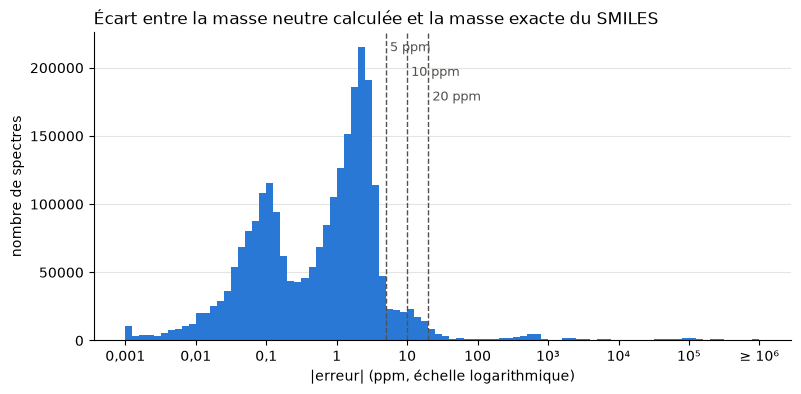

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
# Les erreurs au-delà de 10^6 ppm sont regroupées dans la dernière barre
ax.hist(np.log10(abs_err.dropna().clip(1e-3, 1e6)), bins=90, color="#2a78d6")

for ppm, height in [(5, 0.97), (10, 0.89), (20, 0.81)]:
    ax.axvline(np.log10(ppm), color="#52514e", linestyle="--", linewidth=1)
    ax.text(np.log10(ppm), height, f" {ppm} ppm", transform=ax.get_xaxis_transform(),
            color="#52514e", fontsize=9, va="top")

ticks = range(-3, 7)
labels = ["0,001", "0,01", "0,1", "1", "10", "100", "10³", "10⁴", "10⁵", "≥ 10⁶"]
ax.set_xticks(list(ticks), labels)
ax.set_xlabel("|erreur| (ppm, échelle logarithmique)")
ax.set_ylabel("nombre de spectres")
ax.set_title("Écart entre la masse neutre calculée et la masse exacte du SMILES", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.show()

## 6. Par bibliothèque : part des spectres sous 5, 10 et 20 ppm

C'est le tableau à présenter en réunion.

In [9]:
THRESHOLDS = (5, 10, 20)
below = pd.DataFrame({f"< {t} ppm (%)": abs_err < t for t in THRESHOLDS})

by_lib = below.groupby(meta["ingest_lib"], observed=True).mean().mul(100).round(1)
by_lib.insert(0, "n_spectres", meta.groupby("ingest_lib", observed=True).size())
by_lib.loc["TOUTES"] = [len(meta), *below.mean().mul(100).round(1)]
by_lib.astype({"n_spectres": int}).sort_values("< 10 ppm (%)")

,n_spectres,< 5 ppm (%),< 10 ppm (%),< 20 ppm (%)
ingest_lib,,,,
riken,347171,57.0,73.7,88.5
massbank,101727,88.5,89.8,90.6
gnps,220849,90.7,92.4,93.4
mona,92416,91.5,93.4,94.0
TOUTES,2539608,92.5,95.1,97.3
drug_plus,2545,96.4,96.5,96.5
msdial,40765,99.8,99.8,99.8
masaryk,652,99.5,99.8,100.0
enveda-np-examples,1184,97.6,99.8,99.9


### Décalage systématique par bibliothèque

Sur l'adduct le plus fréquent, `[M+H]+`, l'erreur **médiane** de chaque bibliothèque devrait être proche de 0. Un décalage commun à toute une bibliothèque évoque plutôt la calibration des instruments que le parser.

In [10]:
mh = (meta["adduct"] == "[M+H]+") & (abs_err < 50)
meta[mh].groupby("ingest_lib", observed=True)["error_ppm"].median().round(2).to_frame("erreur médiane [M+H]+ (ppm)")

,erreur médiane [M+H]+ (ppm)
ingest_lib,
drug_plus,0.00
enveda-180,2.22
gnps,0.21
masaryk,0.58
massbank,0.02
mona,0.01
msdial,-0.00
pluskal_ms2,0.01
riken,-0.07


## 7. Par adduct : erreur médiane et part sous 20 ppm

Une **erreur médiane loin de 0** signale un décalage systématique : soit un bug du parser pour cet adduct, soit une étiquette fausse dans les données. Les adducts où la plupart des spectres sont hors tolérance sont listés à part.

In [11]:
by_adduct = pd.DataFrame({
    "n_spectres": meta.groupby("adduct", observed=True).size(),
    "erreur_mediane_ppm": meta.groupby("adduct", observed=True)["error_ppm"].median().round(2),
    "< 20 ppm (%)": (abs_err < 20).groupby(meta["adduct"], observed=True).mean().mul(100).round(1),
})

print("Adducts d'au moins 100 spectres, du moins bon au meilleur :")
by_adduct[by_adduct["n_spectres"] >= 100].sort_values("< 20 ppm (%)").head(25)

Adducts d'au moins 100 spectres, du moins bon au meilleur :


,n_spectres,erreur_mediane_ppm,< 20 ppm (%)
adduct,,,
[M-H5O3]+,230,-2705.88,7.0
[M-CH3]-,619,-475.45,9.0
[M-H2]2-,103,1.98,42.7
[M]-,446,-1.24,76.0
[M-2H2O+H]+,3439,-0.01,81.7
[M-H2O-H]-,285,-0.10,87.7
[M+2H]2+,1717,0.01,87.9
[M-2H]-,454,-0.02,90.1
[M-H2O+H]+,21682,-0.02,92.3


In [12]:
suspects = by_adduct[by_adduct["< 20 ppm (%)"] < 50].sort_values("n_spectres", ascending=False)
print(f"{len(suspects)} adducts dont la majorité des spectres est à plus de 20 ppm :")
suspects

15 adducts dont la majorité des spectres est à plus de 20 ppm :


,n_spectres,erreur_mediane_ppm,< 20 ppm (%)
adduct,,,
[M-CH3]-,619,-475.45,9.0
[M-H5O3]+,230,-2705.88,7.0
[M-H2]2-,103,1.98,42.7
[M-C3H6NO2]-,72,1941.42,0.0
[M+HNa]2+,44,934.05,11.4
[M+CH3]+,18,525.43,0.0
[Cat]2+,15,NaN,0.0
[M+C2H2NaO2]-,15,6848.13,0.0
[M-CH3F2O2]-,11,45.02,0.0


### Bug du parser ou étiquettes douteuses ?

Un bug du parser pour un adduct décalerait la masse d'une **même quantité de daltons pour toutes les molécules** concernées. Mais un tel décalage peut aussi venir des données. Pour trancher, on regarde le nombre de molécules et la dispersion de l'écart en Da.

Un décalage constant qui ne correspond à aucune formule chimique ne peut pas venir d'une mauvaise lecture de la formule. Par exemple, −1,418 Da est impossible, car la masse d'un groupe d'atomes est toujours proche d'un nombre entier.

In [13]:
err_da = meta["neutral_mass"] - meta["exact_mass"]
sel = meta["adduct"].isin(suspects.index[suspects["n_spectres"] >= 50])
grouped = err_da[sel].groupby(meta.loc[sel, "adduct"], observed=True)

pd.DataFrame({
    "n_spectres": grouped.size(),
    "n_molecules": meta[sel].groupby("adduct", observed=True)["inchikey14"].nunique(),
    "ecart_q10_da": grouped.quantile(0.1).round(3),
    "ecart_median_da": grouped.median().round(3),
    "ecart_q90_da": grouped.quantile(0.9).round(3),
})

,n_spectres,n_molecules,ecart_q10_da,ecart_median_da,ecart_q90_da
adduct,,,,,
[M-H2]2-,103,46,-0.059,0.001,604.455
[M-H5O3]+,230,155,-1.421,-1.418,-1.414
[M-CH3]-,619,170,-0.441,-0.350,-0.108
[M-C3H6NO2]-,72,21,-0.390,1.572,1.662


## 8. Le cas `[M]+`

Pour `[M]+`, la molécule porte elle-même la charge. On regarde l'écart **en daltons** selon la charge formelle du SMILES : un écart constant d'environ 0,00055 Da, la masse d'un électron, signalerait une convention différente entre notre formule et `ExactMolWt`.

In [14]:
from rdkit.Chem import Descriptors

from casmi.mass import ELECTRON_MASS, element_mass

# ExactMolWt d'une molécule chargée tient-il compte de l'électron ?
for smi in ["C[N+](C)(C)C", "CN(C)C"]:
    mol = Chem.MolFromSmiles(smi)
    atoms = sum(element_mass(a.GetSymbol()) for a in Chem.AddHs(mol).GetAtoms())
    print(f"{smi:14s} ExactMolWt − somme des atomes = {Descriptors.ExactMolWt(mol) - atoms:+.6f} Da")
print(f"masse de l'électron            = {ELECTRON_MASS:.6f} Da")

C[N+](C)(C)C   ExactMolWt − somme des atomes = -0.000549 Da
CN(C)C         ExactMolWt − somme des atomes = -0.000000 Da
masse de l'électron            = 0.000549 Da


In [15]:
m_plus = meta[meta["adduct"] == "[M]+"].copy()


def formal_charge(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.GetFormalCharge(mol) if mol is not None else np.nan


m_plus["charge_smiles"] = m_plus["normalized_smiles"].map(
    {s: formal_charge(s) for s in m_plus["normalized_smiles"].unique()}
)
m_plus["erreur_da"] = m_plus["neutral_mass"] - m_plus["exact_mass"]

print(f"{len(m_plus):,} spectres [M]+")
m_plus.groupby("charge_smiles")["erreur_da"].describe(percentiles=[0.1, 0.5, 0.9]).round(5)

8,818 spectres [M]+


,count,mean,std,min,10%,50%,90%,max
charge_smiles,,,,,,,,
0,2772.0,0.32151,12.24429,-13.03923,-0.00018,0.00005,0.00308,640.14062
1,6041.0,0.02847,1.09462,-0.34988,0.00000,0.00054,0.00073,79.96415
2,5.0,0.00005,0.00000,0.00005,0.00005,0.00005,0.00005,0.00005


## 9. Comparaison avec `precursor_error_ppm` du jeu de données

Si notre parser fait le même calcul que les auteurs du jeu de données, les deux erreurs doivent être quasi identiques. La corrélation sur tout le jeu n'est pas informative, parce que les erreurs énormes la dominent. On regarde donc, pour chaque adduct fréquent et pour les spectres à moins de 50 ppm, l'écart médian entre les deux erreurs, converti en daltons sur l'ion.

In [16]:
ok = abs_err < 50
diff_da = (meta["error_ppm"] - meta["precursor_error_ppm"]) * 1e-6 * meta["precursor_mz"]

comparison = pd.DataFrame({
    "n_spectres": ok.groupby(meta["adduct"], observed=True).sum(),
    "ecart_median_da": diff_da[ok].groupby(meta.loc[ok, "adduct"], observed=True).median().round(6),
})
print(f"Pour comparaison : masse de l'électron = {ELECTRON_MASS:.6f} Da, masse de H = {element_mass('H'):.6f} Da")
comparison[comparison["n_spectres"] >= 5000].sort_values("n_spectres", ascending=False)

Pour comparaison : masse de l'électron = 0.000549 Da, masse de H = 1.007825 Da


,n_spectres,ecart_median_da
adduct,,
[M+H]+,1298731,0.000019
[M-H]-,451914,-0.000549
[2M+Na]+,190019,0.000501
[M+Na]+,172836,-0.000582
[2M+H]+,92012,0.000341
[M+CH2O2-H]-,83147,-1.007241
[2M-H]-,56146,-0.000563
[M+NH4]+,51680,-0.000540
[M+Cl]-,27469,-0.000548


## 10. Les erreurs énormes (à signaler à A)

Au-delà de 1000 ppm, ce n'est plus une erreur de mesure mais une étiquette fausse. L'écart en daltons, arrondi, aide à deviner laquelle : environ 1,008 Da pour un hydrogène de trop ou de moins, environ 21,98 Da pour Na confondu avec H, etc.

In [17]:
huge = abs_err > 1000
print(f"Spectres avec |erreur| > 1000 ppm : {huge.sum():,} ({huge.mean():.2%})")

pd.DataFrame({
    "n_spectres": meta[huge].groupby("ingest_lib", observed=True).size(),
    "% de la bibliothèque": huge.groupby(meta["ingest_lib"], observed=True).mean().mul(100).round(2),
}).sort_values("n_spectres", ascending=False)

Spectres avec |erreur| > 1000 ppm : 25,518 (1.00%)


,n_spectres,% de la bibliothèque
ingest_lib,,
riken,11010.0,3.17
gnps,10622.0,4.81
mona,2104.0,2.28
massbank,1618.0,1.59
drug_plus,89.0,3.50
msdial,65.0,0.16
pluskal_ms2,5.0,0.00
spectraverse,5.0,0.01
enveda-180,NaN,0.00


In [18]:
print("Écarts les plus fréquents (en Da, arrondis à 0,01) :")
(meta.loc[huge, "neutral_mass"] - meta.loc[huge, "exact_mass"]).round(2).value_counts().head(15)

Écarts les plus fréquents (en Da, arrondis à 0,01) :


-1.01     3098
 21.98    1172
 35.98    1052
-1.00      748
 35.97     668
 34.97     618
-18.01     546
-2.02      543
-2.01      456
 97.97     396
 5.03      321
 17.03     277
 71.95     263
 1.00      203
 18.01     193
Name: count, dtype: int64

## Conclusions

**1. Le parser couvre tout le jeu de données.** 120 des 121 adducts sont interprétés. Seul `[Cat]2+` (15 spectres) est refusé, comme prévu : ce n'est pas un adduct au sens `[nM ± X]z±`. Les 277 566 SMILES distincts sont tous lisibles par RDKit.

**2. Aucun bug détecté dans `mass.py`.** Pour tous les adducts fréquents, l'erreur médiane reste à moins de 1,5 ppm de 0. Sur l'ensemble du jeu : **92,5 % des spectres à moins de 5 ppm, 95,1 % à moins de 10 ppm, 97,3 % à moins de 20 ppm.**

**3. La précision dépend fortement de la bibliothèque.** enveda-180, pluskal_ms2, spectraverse, msdial et masaryk sont proches de 100 % à moins de 10 ppm. riken est nettement moins précise (57 % à moins de 5 ppm, 73,7 % à moins de 10 ppm, 88,5 % à moins de 20 ppm). gnps, mona et massbank plafonnent entre 90 et 94 % à moins de 20 ppm. Ces plafonds limiteront le rappel du filtre par masse (tâche B1.3).

**4. Décalage d'environ +2 ppm dans les bibliothèques Enveda.** Pour `[M+H]+`, l'erreur médiane vaut +2,2 ppm dans enveda-180 et +2,0 ppm dans enveda-np-examples, contre environ 0 ailleurs. C'est probablement la calibration des instruments, pas le parser. À garder en tête pour choisir la tolérance, surtout si le test provient d'instruments similaires.

**5. Le cas `[M]+` : un écart d'exactement une masse d'électron.** Pour les SMILES déjà chargés, l'écart médian vaut +0,00054 Da, car `ExactMolWt` de RDKit retire la masse de l'électron pour un ion, alors que notre M l'inclut. Cela représente environ 1 ppm, ce qui est négligeable pour le filtre mais à documenter, car le catalogue stockera la masse de l'ion pour ces molécules. Les SMILES neutres étiquetés `[M]+`, qui sont des cations radicaux, n'ont pas d'écart.

**6. La colonne `precursor_error_ppm` du jeu n'est pas une référence fiable.** Pour `[M+H]+` et `[M]+`, elle concorde avec notre calcul. Mais pour la plupart des autres adducts (`[M-H]-`, `[M+Na]+`, `[M+K]+`, `[M+NH4]+`, `[M+Cl]-`…), elle en diffère d'environ une masse d'électron (0,00055 Da) : les auteurs ne traitent pas l'électron comme nous, alors que notre formule est celle du plan, vérifiée par les tests calculés à la main. Pour `[M+CH2O2-H]-`, l'écart vaut même un atome d'hydrogène entier (1,007 Da), alors que notre erreur pour cet adduct est quasi nulle (99,9 % à moins de 20 ppm).

**7. Étiquettes douteuses, à transmettre à A pour le nettoyage :**
- `[Cat]2+` : 15 spectres non interprétables ;
- 6 087 spectres dont la charge de l'adduct contredit le mode d'ionisation (5 285 en mode positif avec un adduct négatif, 802 dans le sens inverse) ;
- 25 518 spectres (1,0 %) à plus de 1000 ppm, surtout dans riken, gnps (4,8 % de la bibliothèque), mona et massbank. Les écarts typiques trahissent un adduct mal étiqueté : −1,008 Da (un H de trop ou de moins), +21,98 Da (Na pris pour H), +35,98 Da (Cl pris pour une perte de H), −18,01 Da (H₂O), +17,03 Da (NH₄ pris pour H) ;
- `[M-H5O3]+` : 230 spectres sur 155 molécules, avec un décalage constant de −1,418 Da. Aucune formule chimique n'explique cet écart, donc l'erreur vient des données (215 spectres dans gnps), pas du parser ;
- `[M-CH3]-` : 619 spectres sur 170 molécules (riken, massbank), avec des écarts dispersés entre −0,44 et −0,11 Da (10e et 90e percentiles) qui ne correspondent à aucune formule, donc des précurseurs douteux.

**Proposition pour le filtre qualité `keep` de A :** exclure les adducts non interprétables, les incohérences charge/mode, et les spectres à plus de 1000 ppm.